In [18]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from datetime import timedelta
from concurrent.futures import ThreadPoolExecutor, as_completed 
from threading import Lock
import os 

from sklearn.preprocessing import MinMaxScaler
from sklearn.metrics import mean_squared_error, mean_absolute_error, r2_score
from sklearn.model_selection import train_test_split, KFold

from tensorflow.keras.models import Sequential
from tensorflow.keras.layers import LSTM, Dense, Dropout
from tensorflow.keras.callbacks import EarlyStopping
import tensorflow as tf 

# Пример настройки GPU для TensorFlow (если используется и MAX_MODEL_WORKERS > 1)
gpus = tf.config.experimental.list_physical_devices('GPU')
if gpus:
    try:
        for gpu in gpus:
            tf.config.experimental.set_memory_growth(gpu, True)
            print(f"Enabled memory growth for {len(gpus)} GPU(s)")
    except RuntimeError as e:
        print(f"Error setting memory growth: {e}. Must be set before GPU init.")



from tinkoff.invest import Client, CandleInterval, RequestError
from tinkoff.invest.utils import now, quotation_to_decimal

try:
    import pandas_ta as ta
except ImportError:
    print("Библиотека pandas_ta не найдена. Пожалуйста, установите ее: pip install pandas_ta")
    # exit()

from config import TOKEN

print_lock = Lock()

import warnings
warnings.filterwarnings("ignore")


In [2]:
# --- Параметры конфигурации (общие) ---
TINKOFF_API_TOKEN = TOKEN
INSTRUMENT_FIGI = "BBG004730N88"  # SBER
FEATURE_COLUMN = 'close'
Z_SCORE_THRESHOLD = 3
N_CV_SPLITS = 4
MAX_CV_WORKERS = min(N_CV_SPLITS, (os.cpu_count() or 1) * 2)
TEST_SPLIT_SIZE = 0.2
RANDOM_STATE = 42

SMA_PERIODS = [1, 5, 10]
MACD_FAST = 12
MACD_SLOW = 26
MACD_SIGNAL = 9
ATR_PERIOD = 14
BBANDS_PERIOD = 20
BBANDS_STD_DEV = 2
RSI_PERIOD = 14
STOCH_K = 14
STOCH_D = 3
STOCH_SMOOTH_K = 3



Блок 0: Вспомогательные функции

Преобразует CandleInterval из Tinkoff API в объект timedelta.

In [3]:
def get_timedelta_from_candle_interval(interval: CandleInterval) -> timedelta:
    if interval == CandleInterval.CANDLE_INTERVAL_1_MIN:
        return timedelta(minutes=1)
    elif interval == CandleInterval.CANDLE_INTERVAL_5_MIN:
        return timedelta(minutes=5)
    elif interval == CandleInterval.CANDLE_INTERVAL_10_MIN:
        return timedelta(minutes=10)
    elif interval == CandleInterval.CANDLE_INTERVAL_15_MIN:
        return timedelta(minutes=15)
    elif interval == CandleInterval.CANDLE_INTERVAL_30_MIN:
        return timedelta(minutes=30)
    elif interval == CandleInterval.CANDLE_INTERVAL_HOUR:
        return timedelta(hours=1)
    elif interval == CandleInterval.CANDLE_INTERVAL_2_HOUR:
        return timedelta(hours=2)
    elif interval == CandleInterval.CANDLE_INTERVAL_4_HOUR:
        return timedelta(hours=4)
    elif interval == CandleInterval.CANDLE_INTERVAL_DAY:
        return timedelta(days=1)
    elif interval == CandleInterval.CANDLE_INTERVAL_WEEK:
        return timedelta(weeks=1)
    elif interval == CandleInterval.CANDLE_INTERVAL_MONTH:
        return timedelta(days=30)  # Приблизительно, для общего случая
    else:
        with print_lock:
            print(f"Предупреждение: Неизвестный интервал свечи {interval}, используется 1 минута по умолчанию.")
        return timedelta(minutes=1)



Блок 1: Загрузка и первичная обработка данных

Загружает исторические данные по свечам с Tinkoff Invest API.

In [4]:
def get_tinkoff_candles(token, figi, days, interval, model_name=""):
    with print_lock:
        print(f"[{model_name}] Загрузка данных: {days} дней, интервал {interval.name}")

    def fetch_day_data(day_offset):
        with Client(token) as client:
            end_dt = now() - timedelta(days=day_offset)
            start_dt = end_dt - timedelta(days=1)
            try:
                candles = list(client.get_all_candles(
                    figi=figi,
                    from_=start_dt,
                    to=end_dt,
                    interval=interval
                ))
                return candles
            except RequestError as e:
                with print_lock:
                    print(f"[{model_name}] Ошибка при загрузке данных за {start_dt.date()}: {e}")
                return []

    max_fetch_workers = min(10, days if days > 0 else 1)
    all_candles_nested = []
    with ThreadPoolExecutor(max_workers=max_fetch_workers) as executor:
        futures = [executor.submit(fetch_day_data, day_offset) for day_offset in range(days)]
        for future in as_completed(futures):  # Использование as_completed для потенциально более быстрой обработки
            all_candles_nested.append(future.result())

    all_candles = [candle for sublist in all_candles_nested for candle in sublist if sublist]

    if not all_candles:
        with print_lock:
            print(f"[{model_name}] Не удалось загрузить свечи.")
        return pd.DataFrame()

    df = pd.DataFrame([{
        'time': pd.Timestamp(c.time).tz_localize(None),
        'open': float(quotation_to_decimal(c.open)),
        'high': float(quotation_to_decimal(c.high)),
        'low': float(quotation_to_decimal(c.low)),
        'close': float(quotation_to_decimal(c.close)),
        'volume': c.volume
    } for c in all_candles])

    if df.empty:
        return pd.DataFrame()

    df = df.drop_duplicates(subset=['time'])
    df = df.set_index('time').sort_index()
    df.dropna(inplace=True)

    with print_lock:
        print(f"[{model_name}] Загружено всего {len(df)} уникальных свечей.")
        print(f"[{model_name}] Размер DataFrame после загрузки и базовой очистки: {df.shape}")
    return df



Добавляет технические индикаторы в DataFrame.

In [5]:
def add_technical_indicators(df: pd.DataFrame, model_name="") -> pd.DataFrame:
    if not isinstance(df.index, pd.DatetimeIndex):
        try:
            df.index = pd.to_datetime(df.index)
        except Exception as e:
            with print_lock:
                print(
                    f"[{model_name}] Ошибка: Индекс DataFrame не является DatetimeIndex и не может быть преобразован: {e}")
            return df

    is_future_ta = "-future_TA" in model_name
    if not is_future_ta:
        with print_lock:
            print(f"[{model_name}] Добавление технических индикаторов... Исходный размер df: {df.shape}")

    df_ta = df.copy()
    rename_map = {}
    for col_standard in ['open', 'high', 'low', 'close', 'volume']:
        if col_standard not in df_ta.columns and col_standard.capitalize() in df_ta.columns:
            rename_map[col_standard.capitalize()] = col_standard
    if rename_map:
        df_ta.rename(columns=rename_map, inplace=True)
    df_ta.columns = df_ta.columns.str.lower()

    for period in SMA_PERIODS:
        df_ta[f'sma_{period}'] = ta.sma(df_ta['close'], length=period)
    macd = ta.macd(df_ta['close'], fast=MACD_FAST, slow=MACD_SLOW, signal=MACD_SIGNAL)
    if macd is not None and not macd.empty: df_ta = pd.concat([df_ta, macd], axis=1)
    df_ta['atr'] = ta.atr(df_ta['high'], df_ta['low'], df_ta['close'], length=ATR_PERIOD)
    bbands = ta.bbands(df_ta['close'], length=BBANDS_PERIOD, std=BBANDS_STD_DEV)
    if bbands is not None and not bbands.empty: df_ta = pd.concat([df_ta, bbands], axis=1)
    df_ta['rsi'] = ta.rsi(df_ta['close'], length=RSI_PERIOD)
    stoch = ta.stoch(df_ta['high'], df_ta['low'], df_ta['close'], k=STOCH_K, d=STOCH_D, smooth_k=STOCH_SMOOTH_K)
    if stoch is not None and not stoch.empty: df_ta = pd.concat([df_ta, stoch], axis=1)

    if 'volume' in df_ta.columns:
        df_ta['obv'] = ta.obv(df_ta['close'], df_ta['volume'])
    elif not is_future_ta:
        with print_lock:
            print(f"[{model_name}] Предупреждение: Колонка 'volume' отсутствует, OBV не рассчитан.")

    if 'volume' in df_ta.columns and 'close' in df_ta.columns and 'high' in df_ta.columns and 'low' in df_ta.columns:
        df_ta['typical_price_vol'] = ((df_ta['high'] + df_ta['low'] + df_ta['close']) / 3) * df_ta['volume']
        df_ta['cum_vol'] = df_ta['volume'].cumsum()
        df_ta['cum_typical_price_vol'] = df_ta['typical_price_vol'].cumsum()
        df_ta['vwap'] = np.where(df_ta['cum_vol'] != 0, df_ta['cum_typical_price_vol'] / df_ta['cum_vol'], np.nan)
        df_ta.drop(columns=['typical_price_vol', 'cum_vol', 'cum_typical_price_vol'], inplace=True)
    elif not is_future_ta:
        with print_lock:
            print(f"[{model_name}] Предупреждение: Не удалось рассчитать VWAP, отсутствуют необходимые колонки.")

    df_ta.replace([np.inf, -np.inf], np.nan, inplace=True)
    if not is_future_ta:
        initial_nans = df_ta.isnull().sum().max()
        with print_lock:
            print(f"[{model_name}] Технические индикаторы добавлены. NaN в начале: ~{initial_nans}")
            print(f"[{model_name}] Размер df после ТА (до dropna): {df_ta.shape}")
    return df_ta



In [6]:
def remove_outliers_zscore(df, column_name, threshold=3, model_name=""):
    if column_name not in df.columns:
        with print_lock: print(f"[{model_name}] Колонка '{column_name}' не найдена для удаления выбросов.")
        return df.copy()
    series = df[column_name];
    mean = series.mean();
    std = series.std()
    if std == 0 or pd.isna(std):
        with print_lock: print(f"[{model_name}] Std для '{column_name}' 0/NaN. Выбросы не удаляются.")
        return df.copy()
    z_scores = (series - mean) / std;
    outliers_mask = np.abs(z_scores) > threshold
    num_outliers = outliers_mask.sum();
    df_cleaned = df.copy()
    if num_outliers > 0:
        with print_lock:
            print(f"\n[{model_name}] Найдено/удалено {num_outliers} выбросов в '{column_name}' (Z > {threshold}).")
        df_cleaned = df[~outliers_mask]
    else:
        with print_lock:
            print(f"\n[{model_name}] Выбросы в '{column_name}' (Z > {threshold}) не найдены.")
    with print_lock:
        print(f"[{model_name}] DataFrame после удаления выбросов: {df_cleaned.shape}")
    return df_cleaned



In [7]:
def plot_data_with_outliers(original_df, cleaned_df, column_name, threshold, model_name=""):
    if original_df.empty or column_name not in original_df.columns:
        with print_lock: print(f"[{model_name}] Невозможно построить график выбросов: DataFrame пуст/нет колонки.")
        return
    plt.figure(figsize=(15, 7));
    plt.subplot(2, 1, 1)
    plt.plot(original_df.index, original_df[column_name], label=f'Исходные ({column_name})')
    mean_orig = original_df[column_name].mean();
    std_orig = original_df[column_name].std()
    if std_orig > 0 and not pd.isna(std_orig):
        outliers = original_df[np.abs((original_df[column_name] - mean_orig) / std_orig) > threshold]
        if not outliers.empty: plt.scatter(outliers.index, outliers[column_name], color='red',
                                           label=f'Выбросы (Z > {threshold})', s=50, zorder=5)
    plt.title(f'[{model_name}] Данные до удаления выбросов ({column_name})');
    plt.ylabel('Цена');
    plt.legend();
    plt.grid(True)
    plt.subplot(2, 1, 2)
    if not cleaned_df.empty and column_name in cleaned_df.columns:
        plt.plot(cleaned_df.index, cleaned_df[column_name], label=f'После удаления ({column_name})', color='green')
    else:
        plt.text(0.5, 0.5, 'Очищенные данные отсутствуют', ha='center', va='center', transform=plt.gca().transAxes)
    plt.title(f'[{model_name}] Данные после удаления выбросов ({column_name})');
    plt.xlabel('Дата/время');
    plt.ylabel('Цена');
    plt.legend();
    plt.grid(True)
    plt.tight_layout();
    plt.show()



Блок 2: Процесс предобработки данных (Pipeline)

In [8]:
def split_sequences(X_data_scaled, y_data_scaled, n_steps_in, n_steps_out, timestamps_full_data, model_name=""):
    X, y, times_y = [], [], []
    if len(X_data_scaled) < n_steps_in + n_steps_out:
        with print_lock: print(
            f"[{model_name}] Недостаточно данных для seq: {len(X_data_scaled)} < {n_steps_in + n_steps_out}")
        return np.array(X), np.array(y), np.array(times_y)
    for i in range(len(X_data_scaled) - n_steps_in - n_steps_out + 1):
        X.append(X_data_scaled[i:(i + n_steps_in), :])
        y.append(y_data_scaled[(i + n_steps_in):(i + n_steps_in + n_steps_out)])
        times_y.append(timestamps_full_data[i + n_steps_in])
    return np.array(X), np.array(y), np.array(times_y)



In [9]:
def preprocess_data_pipeline(
        token, figi, days, interval,
        target_feature_col, z_threshold,
        n_steps_in, n_steps_out,
        model_name="", plot_outliers_flag=True):
    with print_lock:
        print(f"--- [{model_name}] Начало процесса предобработки данных ---")
    df_raw = get_tinkoff_candles(token, figi, days, interval, model_name=model_name)
    if df_raw.empty:
        with print_lock: print(f"[{model_name}] Ошибка: не удалось загрузить данные. Предобработка прервана.")
        return None, None, None, None, None, None, None
    df_cleaned_pre_ta = remove_outliers_zscore(df_raw.copy(), target_feature_col, threshold=z_threshold,
                                               model_name=model_name)
    if plot_outliers_flag: plot_data_with_outliers(df_raw, df_cleaned_pre_ta, target_feature_col, z_threshold,
                                                   model_name=model_name)
    df_with_ta = add_technical_indicators(df_cleaned_pre_ta, model_name=model_name)
    df_full_features = df_with_ta.dropna().copy()
    with print_lock:
        print(f"[{model_name}] DataFrame после ТА и dropna(): {df_full_features.shape}")
    if df_full_features.empty or len(df_full_features) < n_steps_in + n_steps_out:
        with print_lock: print(
            f"[{model_name}] Недостаточно данных после обработок ({len(df_full_features)}), надо {n_steps_in + n_steps_out}.")
        return None, None, None, None, None, None, df_full_features
    y_data_unscaled = df_full_features[[target_feature_col]].values
    X_feature_names = list(df_full_features.columns)
    X_data_unscaled = df_full_features[X_feature_names].values
    with print_lock:
        print(f"[{model_name}] Признаков для X: {X_data_unscaled.shape[1]}")
    scaler_X = MinMaxScaler();
    X_data_scaled = scaler_X.fit_transform(X_data_unscaled)
    scaler_y = MinMaxScaler();
    y_data_scaled = scaler_y.fit_transform(y_data_unscaled)
    timestamps_for_sequences = df_full_features.index
    X_sequences, y_sequences, times_y_sequences = split_sequences(
        X_data_scaled, y_data_scaled.flatten(),
        n_steps_in, n_steps_out, timestamps_for_sequences, model_name=model_name)
    if X_sequences.shape[0] == 0:
        with print_lock: print(f"[{model_name}] Ошибка: не удалось создать обучающие последовательности.")
        return None, None, None, scaler_X, scaler_y, X_feature_names, df_full_features
    with print_lock:
        print(f"[{model_name}] Предобработка завершена. {X_sequences.shape[0]} последовательностей.")
        print(f"[{model_name}] X_seq: {X_sequences.shape}, y_seq: {y_sequences.shape}")
        print(f"--- [{model_name}] Конец процесса предобработки данных ---\n")
    return X_sequences, y_sequences, times_y_sequences, scaler_X, scaler_y, X_feature_names, df_full_features



Блок 3: Построение, обучение и оценка модели

In [10]:
def build_lstm_model(n_steps_in, n_steps_out, n_features):
    model = Sequential([
        LSTM(70, return_sequences=True, input_shape=(n_steps_in, n_features)), Dropout(0.3),
        LSTM(70, return_sequences=False), Dropout(0.3),
        Dense(50, activation='relu'), Dense(n_steps_out)
    ])
    model.compile(optimizer='adam', loss='mean_squared_error')
    return model



In [11]:
def calculate_regression_metrics(y_true, y_pred):
    if len(y_true) == 0 or len(y_pred) == 0:
        return {m: np.nan for m in ['mse', 'rmse', 'mae', 'r2', 'mse_pct', 'rmse_pct', 'mae_pct', 'r2_pct']}
    mse_raw = mean_squared_error(y_true, y_pred);
    rmse_raw = np.sqrt(mse_raw);
    mae_raw = mean_absolute_error(y_true, y_pred)
    try:
        r2_raw = r2_score(y_true, y_pred)
    except ValueError:
        r2_raw = np.nan
    mean_y_true = np.mean(y_true)
    if np.isclose(mean_y_true, 0) or pd.isna(mean_y_true):
        mse_pct, rmse_pct, mae_pct = np.nan, np.nan, np.nan
    else:
        mae_pct = (mae_raw / abs(mean_y_true)) * 100
        rmse_pct = (rmse_raw / abs(mean_y_true)) * 100
        mse_pct = (mse_raw / (mean_y_true ** 2)) * 100 if not np.isclose(mean_y_true ** 2, 0) else np.nan
    r2_pct = r2_raw * 100 if not np.isnan(r2_raw) else np.nan
    return {'mse': mse_raw, 'rmse': rmse_raw, 'mae': mae_raw, 'r2': r2_raw,
            'mse_pct': mse_pct, 'rmse_pct': rmse_pct, 'mae_pct': mae_pct, 'r2_pct': r2_pct}



In [12]:
def train_fold(fold_num, train_idx, val_idx, X, y_target_scaled,
               scaler_y, n_steps_in, n_steps_out, n_features, model_name="", current_n_cv_splits=N_CV_SPLITS):
    with print_lock: print(
        f"\n--- [{model_name}] Обучение fold {fold_num + 1}/{current_n_cv_splits} (feat={n_features}) ---")
    model = build_lstm_model(n_steps_in, n_steps_out, n_features)
    X_train, y_train_target_scaled = X[train_idx], y_target_scaled[train_idx]
    X_val, y_val_target_scaled = X[val_idx], y_target_scaled[val_idx]
    history = model.fit(X_train, y_train_target_scaled, validation_data=(X_val, y_val_target_scaled),
                        epochs=50, batch_size=32, verbose=0,
                        callbacks=[EarlyStopping(monitor='val_loss', patience=10, restore_best_weights=True)])
    preds_val_target_scaled = model.predict(X_val, verbose=0)
    y_val_inv_1step = scaler_y.inverse_transform(y_val_target_scaled[:, 0].reshape(-1, 1)).flatten()
    preds_val_inv_1step = scaler_y.inverse_transform(preds_val_target_scaled[:, 0].reshape(-1, 1)).flatten()
    fold_metrics = calculate_regression_metrics(y_val_inv_1step, preds_val_inv_1step)
    with print_lock:
        print(f"[{model_name}] Результаты fold {fold_num + 1} (1-й шаг):")
        for name, val in fold_metrics.items():
            unit = " %" if name.endswith('_pct') else ""
            print(f"  {name.upper()}: {val:.4f}{unit if not pd.isna(val) else ''}")
    return {'model': model, 'metrics': fold_metrics, 'history': history, 'fold': fold_num}



In [13]:
def cross_validate_lstm(X_sequences, y_sequences, scaler_y,
                        n_splits, n_steps_in, n_steps_out, n_features,
                        model_name="", max_workers=None):
    effective_max_workers = 0
    if n_splits >= 2:
        effective_max_workers = min(n_splits, max_workers if max_workers is not None else (os.cpu_count() or 1) * 2)
        effective_max_workers = max(1, effective_max_workers)
    with print_lock:
        print(f"\n--- [{model_name}] CV ({n_splits} фолдов, до {effective_max_workers} потоков) ---")
    if n_splits < 2:
        with print_lock: print(f"[{model_name}] Предупреждение: n_splits = {n_splits} < 2. CV не выполнена.")
        return None, {}
    kf = KFold(n_splits=n_splits, shuffle=True, random_state=RANDOM_STATE)
    fold_results = [];
    futures = []
    with ThreadPoolExecutor(max_workers=effective_max_workers) as executor:
        for fold_num, (train_idx, val_idx) in enumerate(kf.split(X_sequences, y_sequences)):
            futures.append(executor.submit(train_fold, fold_num, train_idx, val_idx, X_sequences, y_sequences,
                                           scaler_y, n_steps_in, n_steps_out, n_features, model_name,
                                           current_n_cv_splits=n_splits))
        for future in as_completed(futures):
            try:
                fold_results.append(future.result())
            except Exception as e:
                with print_lock:
                    print(f"[{model_name}] Ошибка в фолде CV: {e}")
                    import traceback;
                    print(traceback.format_exc())
    if not fold_results:
        with print_lock: print(f"[{model_name}] CV не дала результатов.")
        return None, {}
    fold_results.sort(key=lambda r: r['fold'])
    best_fold_result = min(fold_results, key=lambda r: r['metrics'].get('mse', float('inf')))
    with print_lock:
        print(f"\n--- [{model_name}] CV завершена ---")
        print(
            f"[{model_name}] Лучшая модель из фолда {best_fold_result['fold'] + 1} (MSE: {best_fold_result['metrics'].get('mse', float('inf')):.4f})")
        print(f"[{model_name}] Метрики лучшей модели (валид. набор, 1-й шаг):")
        for name, val in best_fold_result['metrics'].items():
            unit = " %" if name.endswith('_pct') else ""
            print(f"  {name.upper()}: {val:.4f}{unit if not pd.isna(val) else ''}")
    return best_fold_result['model'], best_fold_result['metrics']



In [14]:
def final_test_and_plot(model, X_test, y_test_target_scaled, scaler_y,
                        times_y_test, n_steps_out, target_feature_name, model_name=""):
    with print_lock:
        print(f"\n--- [{model_name}] Финальное тестирование ---")
    if X_test.shape[0] == 0:
        with print_lock: print(f"[{model_name}] Тестовая выборка пуста. Тест не проводится.")
        return
    preds_test_target_scaled = model.predict(X_test, verbose=0)
    y_test_inv_1step = scaler_y.inverse_transform(y_test_target_scaled[:, 0].reshape(-1, 1)).flatten()
    preds_test_inv_1step = scaler_y.inverse_transform(preds_test_target_scaled[:, 0].reshape(-1, 1)).flatten()
    test_metrics_1step = calculate_regression_metrics(y_test_inv_1step, preds_test_inv_1step)
    with print_lock:
        print(f"[{model_name}] Метрики на тест. выборке (1-й шаг):")
        for name, val in test_metrics_1step.items():
            unit = " %" if name.endswith('_pct') else ""
            print(f"  {name.upper()}: {val:.4f}{unit if not pd.isna(val) else ''}")
    result_df = pd.DataFrame({'datetime': times_y_test, 'actual_close_1step': y_test_inv_1step,
                              'predicted_close_1step': preds_test_inv_1step}).set_index('datetime').sort_index()
    plt.figure(figsize=(15, 6))
    plt.plot(result_df.index, result_df['actual_close_1step'], label=f'Факт ({target_feature_name}, 1-й шаг)')
    plt.plot(result_df.index, result_df['predicted_close_1step'], label=f'Прогноз ({target_feature_name}, 1-й шаг)',
             linestyle='--')
    plt.title(f"[{model_name}] Факт/Прогноз ({target_feature_name}, 1-й шаг) на тест. выборке")
    plt.xlabel("Дата/время");
    plt.ylabel(f"Цена ({target_feature_name})");
    plt.xticks(rotation=45)
    plt.legend();
    plt.grid(True);
    plt.tight_layout();
    plt.show()
    if n_steps_out > 1:
        y_test_inv_all_steps = scaler_y.inverse_transform(y_test_target_scaled)
        preds_test_inv_all_steps = scaler_y.inverse_transform(preds_test_target_scaled)
        all_steps_mse = [mean_squared_error(y_test_inv_all_steps[:, i], preds_test_inv_all_steps[:, i]) for i in
                         range(n_steps_out)]
        avg_mse_all_steps = np.mean(all_steps_mse)
        with print_lock: print(
            f"\n[{model_name}] Средняя MSE по всем {n_steps_out} шагам (тест): {avg_mse_all_steps:.4f}")
        y_test_inv_last_step = y_test_inv_all_steps[:, -1];
        preds_test_inv_last_step = preds_test_inv_all_steps[:, -1]
        plt.figure(figsize=(15, 6))
        plt.plot(times_y_test, y_test_inv_last_step, label=f'Факт ({target_feature_name}, {n_steps_out}-й шаг)')
        plt.plot(times_y_test, preds_test_inv_last_step, label=f'Прогноз ({target_feature_name}, {n_steps_out}-й шаг)',
                 linestyle='--')
        plt.title(f"[{model_name}] Факт/Прогноз ({target_feature_name}, {n_steps_out}-й шаг) на тест. выборке")
        plt.xlabel("Дата/время (начала y)");
        plt.ylabel(f"Цена ({target_feature_name})");
        plt.xticks(rotation=45)
        plt.legend();
        plt.grid(True);
        plt.tight_layout();
        plt.show()



Блок 4: Рекурсивное прогнозирование будущего

In [15]:
def predict_future_recursive(
        model, initial_X_sequence_scaled, scaler_X, scaler_y,
        all_X_feature_names, target_feature_name, num_total_future_steps,
        n_steps_in_model, n_steps_out_model, last_known_full_data_df,
        candle_interval_timedelta, model_name=""):
    with print_lock:
        print(f"\n[{model_name}] Рекурсивный прогноз на {num_total_future_steps} шагов...")
    all_future_preds_y_inv_flat = [];
    current_input_X_scaled = initial_X_sequence_scaled.copy()
    history_df = last_known_full_data_df.iloc[-n_steps_in_model:].copy()
    if not isinstance(history_df.index, pd.DatetimeIndex): history_df.index = pd.to_datetime(history_df.index)
    last_real_timestamp = history_df.index[-1]
    for _ in range(int(np.ceil(num_total_future_steps / n_steps_out_model))):
        if len(all_future_preds_y_inv_flat) >= num_total_future_steps: break
        predicted_y_scaled_chunk = model.predict(current_input_X_scaled, verbose=0)
        predicted_y_inv_chunk = scaler_y.inverse_transform(predicted_y_scaled_chunk).flatten()
        num_to_add = min(len(predicted_y_inv_chunk), num_total_future_steps - len(all_future_preds_y_inv_flat))
        all_future_preds_y_inv_flat.extend(predicted_y_inv_chunk[:num_to_add])
        if len(all_future_preds_y_inv_flat) >= num_total_future_steps: break
        new_rows_list = [];
        current_synth_ts = history_df.index[-1]
        for i in range(len(predicted_y_inv_chunk)):
            current_synth_ts += candle_interval_timedelta;
            pred_close = predicted_y_inv_chunk[i]
            new_row = {'open': pred_close, 'high': pred_close, 'low': pred_close, 'close': pred_close,
                       'volume': history_df['volume'].iloc[-1] if 'volume' in history_df.columns else 0}
            for col in all_X_feature_names:
                if col not in new_row: new_row[col] = np.nan
            new_rows_list.append(pd.DataFrame(new_row, index=[current_synth_ts]))
        if not new_rows_list: continue
        history_df_ext_ohlcv = pd.concat([history_df] + new_rows_list)
        lookback_ta = max(BBANDS_PERIOD, MACD_SLOW, ATR_PERIOD, RSI_PERIOD, STOCH_K, 50) + 20
        start_idx_recalc = max(0, len(history_df_ext_ohlcv) - (lookback_ta + len(predicted_y_inv_chunk)))
        df_for_recalc = history_df_ext_ohlcv.iloc[start_idx_recalc:].copy()
        df_with_new_ta = add_technical_indicators(df_for_recalc, model_name=f"{model_name}-future_TA")
        df_with_new_ta.dropna(inplace=True)
        if df_with_new_ta.empty or len(df_with_new_ta) < n_steps_in_model:
            with print_lock: print(f"[{model_name}] Ошибка predict_future: мало данных после ТА. Прогноз остановлен.")
            break
        history_df = df_with_new_ta.iloc[-(n_steps_in_model + len(predicted_y_inv_chunk)):].copy()
        if len(history_df) < n_steps_in_model: history_df = df_with_new_ta.iloc[-n_steps_in_model:].copy()
        if len(history_df) < n_steps_in_model:
            with print_lock: print(f"[{model_name}] Крит. ошибка predict_future: history_df слишком короткий. Стоп.")
            break
        new_X_unscaled_df = history_df[all_X_feature_names].iloc[-n_steps_in_model:]
        if len(new_X_unscaled_df) < n_steps_in_model:
            with print_lock: print(
                f"[{model_name}] Ошибка predict_future: мало данных ({len(new_X_unscaled_df)}) для X_input. Стоп.")
            break
        new_X_unscaled_vals = new_X_unscaled_df.values
        if np.isnan(new_X_unscaled_vals).any(): new_X_unscaled_vals = np.nan_to_num(new_X_unscaled_vals)
        new_X_scaled_vals = scaler_X.transform(new_X_unscaled_vals)
        current_input_X_scaled = new_X_scaled_vals.reshape(1, n_steps_in_model, -1)
    future_preds_array = np.array(all_future_preds_y_inv_flat)
    future_times = pd.to_datetime(
        [last_real_timestamp + candle_interval_timedelta * (i + 1) for i in range(len(future_preds_array))])
    with print_lock:
        print(f"[{model_name}] Рекурсивный прогноз завершен.")
    return future_preds_array, future_times



Блок 5: Основной поток выполнения для одной модели

In [16]:
def run_model_pipeline(model_config):
    model_name = model_config["name"]
    print_lock.acquire();
    print(f"\n\n{'=' * 30} Processing Model: {model_name} {'=' * 30}");
    print_lock.release()
    days_history = model_config["days_history"];
    candle_timeframe = model_config["candle_timeframe"]
    n_steps_in = model_config["n_steps_in"];
    n_steps_out = model_config["n_steps_out"]
    future_predictions_count = model_config["future_predictions"]
    X_sequences_all, y_sequences_all, times_y_all, scaler_X, scaler_y, x_feature_names, df_full_features = preprocess_data_pipeline(
        token=TINKOFF_API_TOKEN, figi=INSTRUMENT_FIGI, days=days_history, interval=candle_timeframe,
        target_feature_col=FEATURE_COLUMN, z_threshold=Z_SCORE_THRESHOLD,
        n_steps_in=n_steps_in, n_steps_out=n_steps_out, model_name=model_name, plot_outliers_flag=False)
    if X_sequences_all is None or X_sequences_all.shape[0] == 0:
        with print_lock: print(f"[{model_name}] Не удалось подготовить данные. Пропуск модели.")
        return
    n_total_features_X = X_sequences_all.shape[2]
    X_trainval, X_test, y_trainval_target_scaled, y_test_target_scaled, times_y_trainval, times_y_test = train_test_split(
        X_sequences_all, y_sequences_all, times_y_all, test_size=TEST_SPLIT_SIZE, shuffle=False,
        random_state=RANDOM_STATE)
    with print_lock:
        print(f"\n[{model_name}] Размеры выборок: Обуч/валид (X): {X_trainval.shape}, Тест (X): {X_test.shape}")
    final_model = None;
    current_n_cv_splits = N_CV_SPLITS
    if X_trainval.shape[0] < current_n_cv_splits and X_trainval.shape[0] >= 2:
        actual_cv_splits = max(2, X_trainval.shape[0] // 2 if X_trainval.shape[0] >= 4 else 2)
        if X_trainval.shape[0] < 2: actual_cv_splits = 0
        with print_lock:
            print(f"[{model_name}] Мало данных для {current_n_cv_splits} фолдов. Используется {actual_cv_splits}.")
        current_n_cv_splits = actual_cv_splits
    elif X_trainval.shape[0] < 2:
        current_n_cv_splits = 0
        with print_lock:
            print(f"[{model_name}] Слишком мало данных ({X_trainval.shape[0]}) для CV.")
    if current_n_cv_splits >= 2:
        best_model_cv, _ = cross_validate_lstm(X_trainval, y_trainval_target_scaled, scaler_y, current_n_cv_splits,
                                               n_steps_in, n_steps_out, n_total_features_X, model_name=model_name,
                                               max_workers=MAX_CV_WORKERS)
        final_model = best_model_cv
    elif X_trainval.shape[0] > 0:
        with print_lock:
            print(f"[{model_name}] Обучение одной модели без CV (мало данных для CV)...")
        final_model = build_lstm_model(n_steps_in, n_steps_out, n_total_features_X)
        val_data_single = None
        if len(X_trainval) > n_steps_in + n_steps_out + 10:  # Simple check for val split
            X_train_single, X_val_single, y_train_single, y_val_single = train_test_split(
                X_trainval, y_trainval_target_scaled, test_size=0.1, shuffle=False, random_state=RANDOM_STATE)
            val_data_single = (X_val_single, y_val_single)
            X_trainval, y_trainval_target_scaled = X_train_single, y_train_single  # Train on smaller part

        final_model.fit(X_trainval, y_trainval_target_scaled, epochs=50, batch_size=32, verbose=0,
                        validation_data=val_data_single,
                        callbacks=[EarlyStopping(monitor='val_loss' if val_data_single else 'loss', patience=10,
                                                 restore_best_weights=True)])
    else:
        with print_lock:
            print(f"[{model_name}] Нет данных для обучения (X_trainval пуст).")

    if final_model:
        if X_test.shape[0] > 0:
            final_test_and_plot(final_model, X_test, y_test_target_scaled, scaler_y,
                                times_y_test, n_steps_out, FEATURE_COLUMN, model_name=model_name)
        else:
            with print_lock: print(f"[{model_name}] Тестовая выборка пуста, финальный тест не проводился.")
        if df_full_features is not None and not df_full_features.empty and \
                len(df_full_features) >= n_steps_in and scaler_X and scaler_y:
            last_N_real_data_unscaled_X_df = df_full_features[x_feature_names].iloc[-n_steps_in:]
            last_N_real_data_scaled_X = scaler_X.transform(last_N_real_data_unscaled_X_df.values)
            initial_sequence_X_for_future = last_N_real_data_scaled_X.reshape(1, n_steps_in, n_total_features_X)
            interval_td = get_timedelta_from_candle_interval(candle_timeframe)
            future_preds_y_inv, future_times = predict_future_recursive(
                model=final_model, initial_X_sequence_scaled=initial_sequence_X_for_future,
                scaler_X=scaler_X, scaler_y=scaler_y, all_X_feature_names=x_feature_names,
                target_feature_name=FEATURE_COLUMN, num_total_future_steps=future_predictions_count,
                n_steps_in_model=n_steps_in, n_steps_out_model=n_steps_out,
                last_known_full_data_df=df_full_features.copy(), candle_interval_timedelta=interval_td,
                model_name=model_name)
            if future_preds_y_inv is not None and len(future_preds_y_inv) > 0:
                plt.figure(figsize=(15, 7));
                context_length = n_steps_in
                real_data_context_values = df_full_features[FEATURE_COLUMN].values[-context_length:]
                real_data_context_times = df_full_features.index[-context_length:]
                plt.plot(real_data_context_times, real_data_context_values, label=f'Реальные ({FEATURE_COLUMN})',
                         marker='.')
                plt.plot(future_times, future_preds_y_inv.flatten(),
                         label=f'Прогноз на {future_predictions_count} ({FEATURE_COLUMN})', marker='x', linestyle='--')
                plt.title(
                    f'[{model_name}] Прогноз {FEATURE_COLUMN} на {future_predictions_count} ({candle_timeframe.name})')
                plt.xlabel('Дата/время');
                plt.ylabel(f"Цена ({FEATURE_COLUMN})");
                plt.xticks(rotation=45)
                plt.legend();
                plt.grid(True);
                plt.tight_layout();
                plt.show()
            else: 
                with print_lock: print(f"[{model_name}] Рекурсивный прогноз не вернул результатов.")
        else: 
            with print_lock: print(f"[{model_name}] Мало данных/нет скейлеров для рекурсивного прогноза.")
    else: 
        with print_lock: print(f"[{model_name}] Модель не обучена. Тест/прогноз пропущены.")
    print_lock.acquire();
    print(f"\n{'=' * 30} Завершение обработки модели: {model_name} {'=' * 30}");
    print_lock.release()



In [ ]:
def create_minute_based_prediction_configs(
        base_days_history=30,
        base_n_steps_in=150,    # Сколько 1-минутных свечей на вход модели
        model_direct_n_steps_out=15 # Сколько 1-минутных свечей модель предсказывает за один раз
    ):
    """
    Создает конфигурации моделей для прогнозирования на 1 час, 10 мин, 5 мин, 1 мин.
    Все модели используют 1-минутный таймфрейм свечей.

    Args:
        base_days_history (int): Количество дней истории для загрузки.
        base_n_steps_in (int): Количество прошлых 1-минутных свечей для входа модели.
        model_direct_n_steps_out (int): Количество 1-минутных свечей, которые модель
                                        предсказывает за один вызов (внутренний n_steps_out).
                                        Рекурсивный прогноз затем соберет полный горизонт.
    Returns:
        list: Список словарей с конфигурациями моделей.
    """
    configs = []
    # Горизонты прогнозирования в минутах
    prediction_horizons_map = {
        "1_hour": 60,  # 1 час = 60 минут
        "10_min": 10,  # 10 минут
        "5_min": 5,    # 5 минут
        "1_min": 1     # 1 минута
    }

    for name_suffix, horizon_total_minutes in prediction_horizons_map.items():
        config = {
            "name": f"Model_1minTF_{name_suffix}_Horizon",
            "days_history": base_days_history,
            "candle_timeframe": CandleInterval.CANDLE_INTERVAL_1_MIN, # Всегда 1 минута
            "n_steps_in": base_n_steps_in,
            # n_steps_out для модели - это сколько она выдает за раз.
            # Если горизонт меньше, чем model_direct_n_steps_out, то можно n_steps_out сделать равным горизонту,
            # но для единообразия архитектуры модели, оставим model_direct_n_steps_out.
            # Рекурсивный прогноз возьмет нужное количество шагов.
            "n_steps_out": model_direct_n_steps_out,
            # future_predictions - это общий желаемый горизонт прогноза в 1-минутных шагах.
            "future_predictions": horizon_total_minutes
        }
        configs.append(config)
    return configs

In [19]:
# --- Эмуляция необходимого класса CandleInterval ---
# В вашем полном коде здесь будет: from tinkoff.invest import CandleInterval
# Это нужно, чтобы скрипт выполнился автономно для демонстрации функции.
class CandleInterval:
    CANDLE_INTERVAL_UNSPECIFIED = 0
    CANDLE_INTERVAL_1_MIN = 1
    CANDLE_INTERVAL_5_MIN = 2
    CANDLE_INTERVAL_10_MIN = 5 # В Tinkoff API 10-минутный интервал имеет значение 5
    CANDLE_INTERVAL_15_MIN = 3
    CANDLE_INTERVAL_HOUR = 4
    # Добавьте другие значения, если они используются в других частях вашего кода,
    # но для create_minute_based_prediction_configs достаточно CANDLE_INTERVAL_1_MIN.

    # Для более красивого вывода имен интервалов (опционально)
    @staticmethod
    def get_name(value):
        names = {
            CandleInterval.CANDLE_INTERVAL_1_MIN: "CANDLE_INTERVAL_1_MIN",
            CandleInterval.CANDLE_INTERVAL_5_MIN: "CANDLE_INTERVAL_5_MIN",
            CandleInterval.CANDLE_INTERVAL_10_MIN: "CANDLE_INTERVAL_10_MIN",
            CandleInterval.CANDLE_INTERVAL_15_MIN: "CANDLE_INTERVAL_15_MIN",
            CandleInterval.CANDLE_INTERVAL_HOUR: "CANDLE_INTERVAL_HOUR",
        }
        return names.get(value, f"UNKNOWN_INTERVAL_{value}")

# --- Функция для создания конфигураций ---
def create_minute_based_prediction_configs(
        base_days_history=30,
        base_n_steps_in=150,
        model_direct_n_steps_out=15
    ):
    """
    Создает конфигурации моделей для прогнозирования на 1 час, 10 мин, 5 мин, 1 мин.
    Все модели используют 1-минутный таймфрейм свечей для входа.

    Примечание: "Лучшие" базовые параметры (base_days_history, base_n_steps_in,
    model_direct_n_steps_out) для вашей LSTM-модели должны быть определены
    путем экспериментов и тюнинга. Эта функция использует переданные
    ей значения как основу для всех генерируемых конфигураций.

    Args:
        base_days_history (int): Количество дней истории для загрузки данных.
        base_n_steps_in (int): Количество прошлых 1-минутных свечей, которые
                               модель использует для одного предсказания (вход модели).
        model_direct_n_steps_out (int): Количество 1-минутных свечей, которые
                                        модель предсказывает за один прямой вызов
                                        (выход модели). Рекурсивный прогноз
                                        затем соберет полный желаемый горизонт.
    Returns:
        list: Список словарей, где каждый словарь представляет конфигурацию модели.
    """
    configs = []
    # Горизонты прогнозирования в минутах, на которые мы хотим получить итоговый прогноз
    prediction_horizons_map = {
        "1_hour_pred": 60,  # Прогноз на 1 час (60 минут)
        "10_min_pred": 10,  # Прогноз на 10 минут
        "5_min_pred": 5,    # Прогноз на 5 минут
        "1_min_pred": 1     # Прогноз на 1 минуту
    }

    for name_suffix, horizon_total_minutes in prediction_horizons_map.items():
        config = {
            "name": f"Model_1minTF_{name_suffix}", # Имя модели
            "days_history": base_days_history,     # Дни истории для загрузки
            "candle_timeframe": CandleInterval.CANDLE_INTERVAL_1_MIN, # Таймфрейм свечей (всегда 1 минута)
            "n_steps_in": base_n_steps_in,         # Входные шаги для модели
            "n_steps_out": model_direct_n_steps_out, # Выходные шаги *прямого* прогноза модели
            "future_predictions": horizon_total_minutes # Общий горизонт рекурсивного прогноза в минутах
        }
        configs.append(config)
    return configs

# --- Основной блок для демонстрации ---
if __name__ == "__main__":
    # Эти параметры определяют "лучшую" базовую конфигурацию вашей LSTM-модели.
    # Их значения являются примером и должны быть подобраны экспериментально.
    BEST_BASE_DAYS_HISTORY = 30        # Например, 30 дней истории
    BEST_BASE_N_STEPS_IN = 150         # Например, модель смотрит на 150 минут (2.5 часа) назад
    BEST_MODEL_DIRECT_N_STEPS_OUT = 15 # Например, модель за раз предсказывает 15 минут вперед

    print("Генерация конфигураций для моделей с 1-минутным таймфреймом и различными горизонтами прогноза.")
    print("Используемые 'лучшие' базовые параметры для всех моделей:")
    print(f"  - Дней истории для загрузки: {BEST_BASE_DAYS_HISTORY}")
    print(f"  - Шагов на вход модели (n_steps_in): {BEST_BASE_N_STEPS_IN}")
    print(f"  - Шагов на прямой выход модели (n_steps_out): {BEST_MODEL_DIRECT_N_STEPS_OUT}\n")

    # Генерация списка конфигураций
    generated_model_configs = create_minute_based_prediction_configs(
        base_days_history=BEST_BASE_DAYS_HISTORY,
        base_n_steps_in=BEST_BASE_N_STEPS_IN,
        model_direct_n_steps_out=BEST_MODEL_DIRECT_N_STEPS_OUT
    )

    print("Сгенерированные конфигурации (запросы для моделей):")
    for i, config in enumerate(generated_model_configs):
        print(f"\n--- Конфигурация {i+1} ---")
        for key, value in config.items():
            if key == "candle_timeframe":
                # Используем get_name для более читаемого вывода
                print(f"  {key}: {CandleInterval.get_name(value)} (raw value: {value})")
            else:
                print(f"  {key}: {value}")

    # Далее эти 'generated_model_configs' можно передавать в ваш основной пайплайн
    # для обучения и запуска моделей, как это было в полном скрипте.
    # Например:
    #
    # model_configs_to_run = generated_model_configs
    #
    # if model_configs_to_run:
    #     # ... ваш код для запуска ThreadPoolExecutor с run_model_pipeline ...
    #     print(f"\nINFO: Подготовлено {len(model_configs_to_run)} конфигураций для запуска.")
    # else:
    #     print("INFO: Конфигурации моделей не сгенерированы.")

Генерация конфигураций для моделей с 1-минутным таймфреймом и различными горизонтами прогноза.
Используемые 'лучшие' базовые параметры для всех моделей:
  - Дней истории для загрузки: 30
  - Шагов на вход модели (n_steps_in): 150
  - Шагов на прямой выход модели (n_steps_out): 15

Сгенерированные конфигурации (запросы для моделей):

--- Конфигурация 1 ---
  name: Model_1minTF_1_hour_pred
  days_history: 30
  candle_timeframe: CANDLE_INTERVAL_1_MIN (raw value: 1)
  n_steps_in: 150
  n_steps_out: 15
  future_predictions: 60

--- Конфигурация 2 ---
  name: Model_1minTF_10_min_pred
  days_history: 30
  candle_timeframe: CANDLE_INTERVAL_1_MIN (raw value: 1)
  n_steps_in: 150
  n_steps_out: 15
  future_predictions: 10

--- Конфигурация 3 ---
  name: Model_1minTF_5_min_pred
  days_history: 30
  candle_timeframe: CANDLE_INTERVAL_1_MIN (raw value: 1)
  n_steps_in: 150
  n_steps_out: 15
  future_predictions: 5

--- Конфигурация 4 ---
  name: Model_1minTF_1_min_pred
  days_history: 30
  candle_ti

Скользящие средние (SMA - Simple Moving Average):

    Периоды: SMA_PERIODS = [1, 5, 10] (для цен закрытия 'close')

    Добавляемые колонки: sma_1, sma_5, sma_10

MACD (Moving Average Convergence Divergence - схождение и расхождение скользящих средних):

    Быстрая EMA: MACD_FAST = 12

    Медленная EMA: MACD_SLOW = 26

    Сигнальная линия (EMA от MACD): MACD_SIGNAL = 9

    Добавляемые колонки

        MACD_12_26_9 (линия MACD)

        MACDh_12_26_9 (гистограмма MACD)

        MACDs_12_26_9 (сигнальная линия)

ATR (Average True Range - Средний истинный диапазон):

    Период: ATR_PERIOD = 14

    Добавляемая колонка: atr (ATR_14)

Bollinger Bands (Полосы Боллинджера):

    Период для SMA: BBANDS_PERIOD = 20

    Количество стандартных отклонений: BBANDS_STD_DEV = 2

    Добавляемые колонки (типичные имена от pandas_ta):

        BBL_20_2.0 (нижняя полоса)

        BBM_20_2.0 (средняя полоса, т.е. SMA(20))

        BBU_20_2.0 (верхняя полоса)

        BBB_20_2.0 (ширина полос - Bollinger Bandwidth)

        BBP_20_2.0 (процент цены относительно полос - %B)

RSI (Relative Strength Index - Индекс Относительной Силы):

    Период: RSI_PERIOD = 14

    Добавляемая колонка: rsi (в вашем коде явно df_ta['rsi'] = ...)

Stochastic Oscillator (Стохастический осциллятор):

    Период %K: STOCH_K = 14

    Период %D (SMA от %K): STOCH_D = 3

    Сглаживание %K: STOCH_SMOOTH_K = 3

    Добавляемые колонки (типичные имена от pandas_ta):

        STOCHk_14_3_3 (линия %K)

        STOCHd_14_3_3 (линия %D)

OBV (On-Balance Volume - Балансовый Объем):

    Рассчитывается на основе close и volume.

    Добавляемая колонка: obv (в вашем коде явно df_ta['obv'] = ...)

VWAP (Volume Weighted Average Price - Средневзвешенная по объему цена):

    Рассчитывается кумулятивно для всего загруженного датасета (а не по дням, как это часто делают для интрадей-торговли).

    Использует high, low, close, volume.

    Добавляемая колонка: vwap

Обнаружено 12 CPU ядер.
INFO: Запуск обучения для 3 моделей.
INFO: Запрошено минимум 12 потоков для моделей.
INFO: Максимальное количество одновременно обучаемых моделей (MAX_MODEL_WORKERS): 3
INFO: Если используется GPU, УБЕДИТЕСЬ, что TensorFlow настроен для роста памяти GPU (memory growth), иначе установите меньшее значение MAX_MODEL_WORKERS (например, 1).
INFO: В противном случае TensorFlow может занять всю память GPU на первой модели, и остальные не запустятся.


============================== Processing Model: Model_1min_TF_30d_hist_5h_pred ==============================
--- [Model_1min_TF_30d_hist_5h_pred] Начало процесса предобработки данных ---
[Model_1min_TF_30d_hist_5h_pred] Загрузка данных: 30 дней, интервал CANDLE_INTERVAL_1_MIN


============================== Processing Model: Model_5min_TF_60d_hist_15h_pred ==============================
--- [Model_5min_TF_60d_hist_15h_pred] Начало процесса предобработки данных ---
[Model_5min_TF_60d_hist_15h_pred] Загрузка данных: 60 д

/home/marcus2tut/.local/lib/python3.11/site-packages/keras/src/layers/rnn/rnn.py:200: UserWarning: Do not pass an `input_shape`/`input_dim` argument to a layer. When using Sequential models, prefer using an `Input(shape)` object as the first layer in the model instead.
  super().__init__(**kwargs)


[Model_1min_TF_30d_hist_5h_pred] Предобработка завершена. 30242 последовательностей.
[Model_1min_TF_30d_hist_5h_pred] X_seq: (30242, 150, 22), y_seq: (30242, 15)
--- [Model_1min_TF_30d_hist_5h_pred] Конец процесса предобработки данных ---


[Model_1min_TF_30d_hist_5h_pred] Размеры выборок: Обуч/валид (X): (24193, 150, 22), Тест (X): (6049, 150, 22)

--- [Model_1min_TF_30d_hist_5h_pred] CV (4 фолдов, до 4 потоков) ---

--- [Model_1min_TF_30d_hist_5h_pred] Обучение fold 1/4 (feat=22) ---

--- [Model_1min_TF_30d_hist_5h_pred] Обучение fold 2/4 (feat=22) ---

--- [Model_1min_TF_30d_hist_5h_pred] Обучение fold 3/4 (feat=22) ---

--- [Model_1min_TF_30d_hist_5h_pred] Обучение fold 4/4 (feat=22) ---
[Model_10min_TF_90d_hist_1d_pred] Результаты fold 3 (1-й шаг):
  MSE: 2.0273
  RMSE: 1.4238
  MAE: 1.0694
  R2: 0.9809
  MSE_PCT: 0.0021 %
  RMSE_PCT: 0.4589 %
  MAE_PCT: 0.3447 %
  R2_PCT: 98.0922 %
[Model_1min_TF_30d_hist_5h_pred] Результаты fold 2 (1-й шаг):
  MSE: 0.1125
  RMSE: 0.3354
  MAE: 0

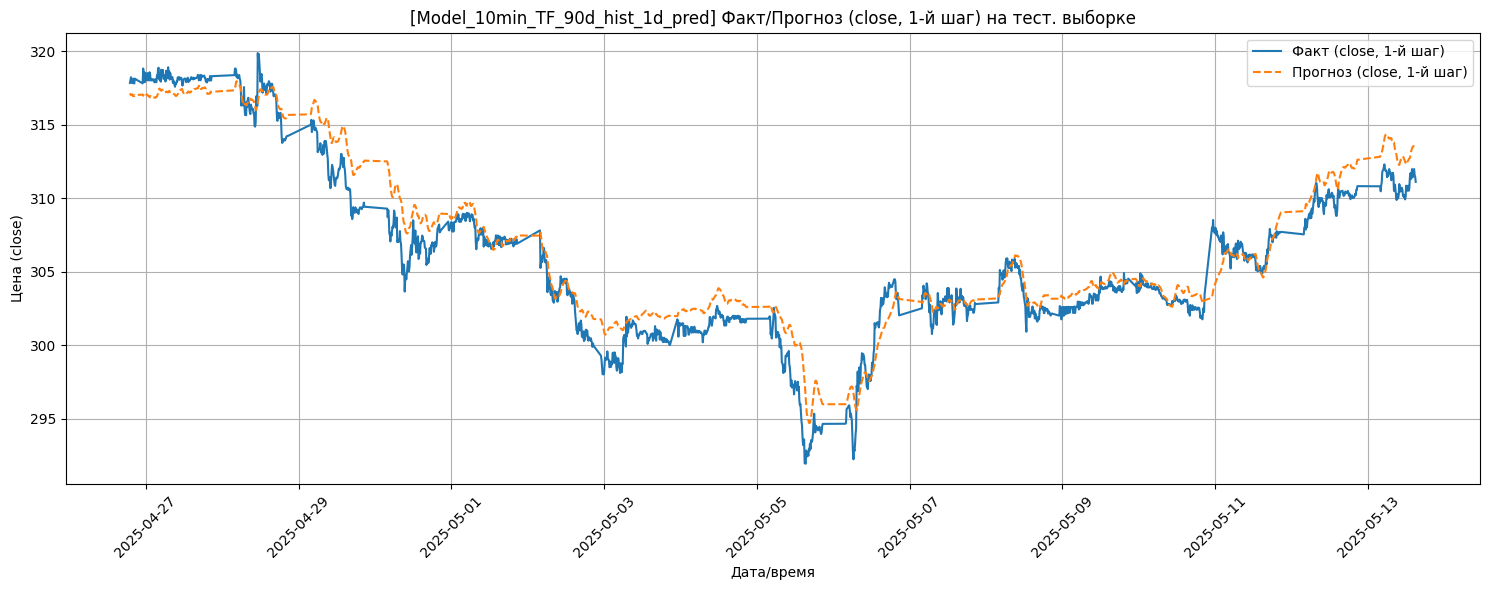


[Model_10min_TF_90d_hist_1d_pred] Средняя MSE по всем 144 шагам (тест): 28.2162


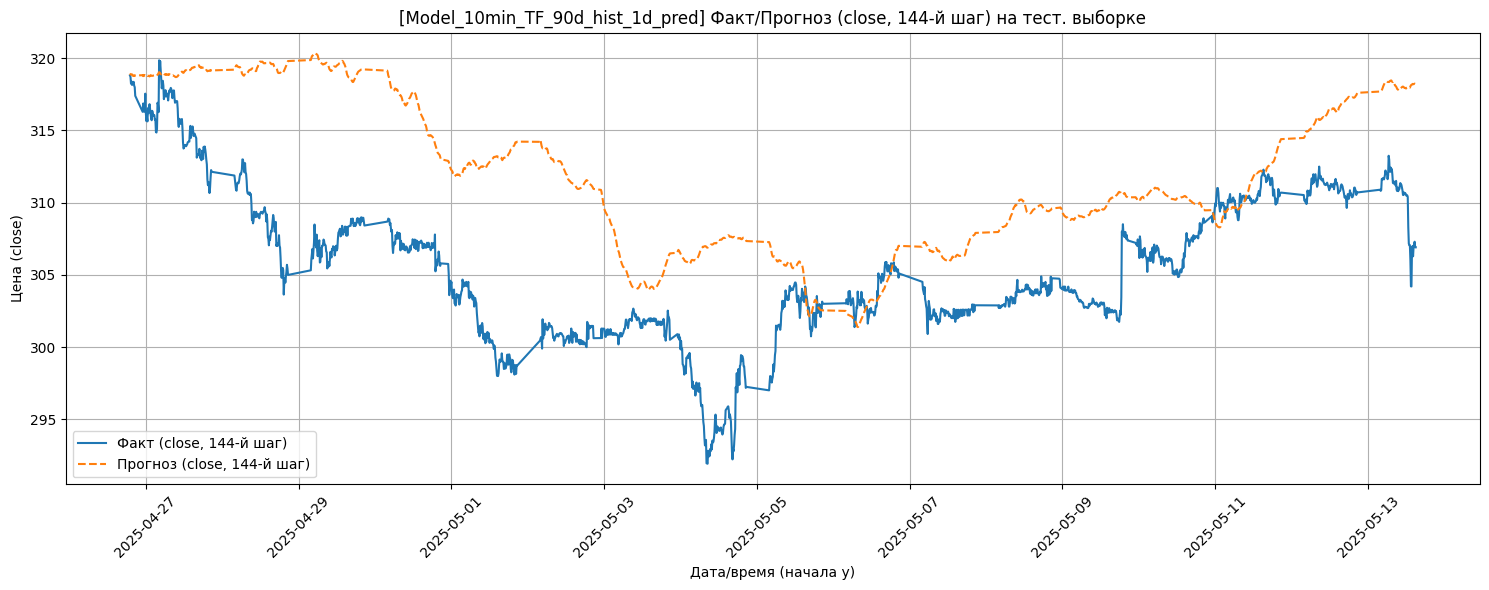


[Model_10min_TF_90d_hist_1d_pred] Рекурсивный прогноз на 144 шагов...
[Model_10min_TF_90d_hist_1d_pred] Рекурсивный прогноз завершен.


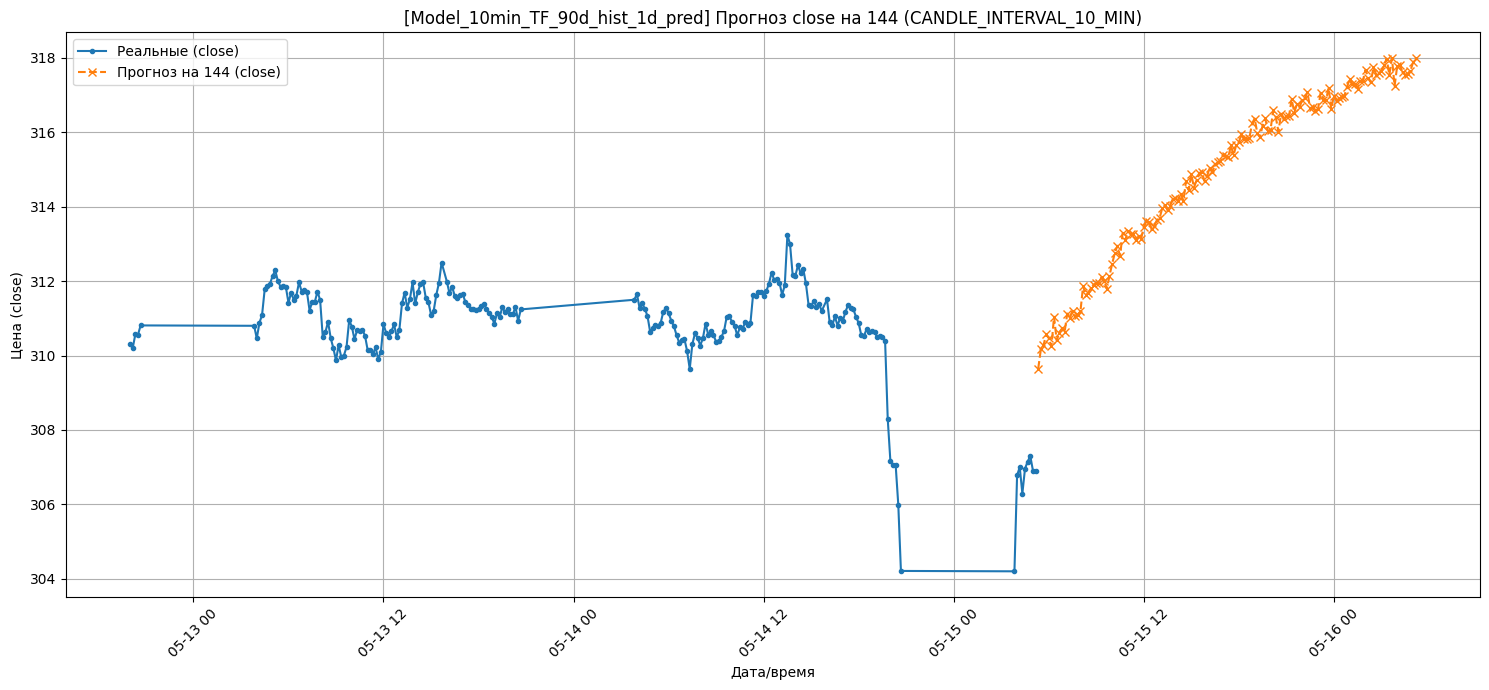


============================== Завершение обработки модели: Model_10min_TF_90d_hist_1d_pred ==============================
[Model_1min_TF_30d_hist_5h_pred] Результаты fold 4 (1-й шаг):
  MSE: 0.0818
  RMSE: 0.2860
  MAE: 0.2111
  R2: 0.9980
  MSE_PCT: 0.0001 %
  RMSE_PCT: 0.0934 %
  MAE_PCT: 0.0689 %
  R2_PCT: 99.8037 %
[Model_5min_TF_60d_hist_15h_pred] Результаты fold 4 (1-й шаг):
  MSE: 1.0057
  RMSE: 1.0028
  MAE: 0.7604
  R2: 0.9923
  MSE_PCT: 0.0011 %
  RMSE_PCT: 0.3266 %
  MAE_PCT: 0.2477 %
  R2_PCT: 99.2337 %
[Model_5min_TF_60d_hist_15h_pred] Результаты fold 1 (1-й шаг):
  MSE: 0.9724
  RMSE: 0.9861
  MAE: 0.7124
  R2: 0.9930
  MSE_PCT: 0.0010 %
  RMSE_PCT: 0.3210 %
  MAE_PCT: 0.2319 %
  R2_PCT: 99.2987 %
[Model_5min_TF_60d_hist_15h_pred] Результаты fold 2 (1-й шаг):
  MSE: 1.4657
  RMSE: 1.2107
  MAE: 0.9615
  R2: 0.9899
  MSE_PCT: 0.0016 %
  RMSE_PCT: 0.3943 %
  MAE_PCT: 0.3131 %
  R2_PCT: 98.9855 %
[Model_5min_TF_60d_hist_15h_pred] Результаты fold 3 (1-й шаг):
  MSE: 0.9148


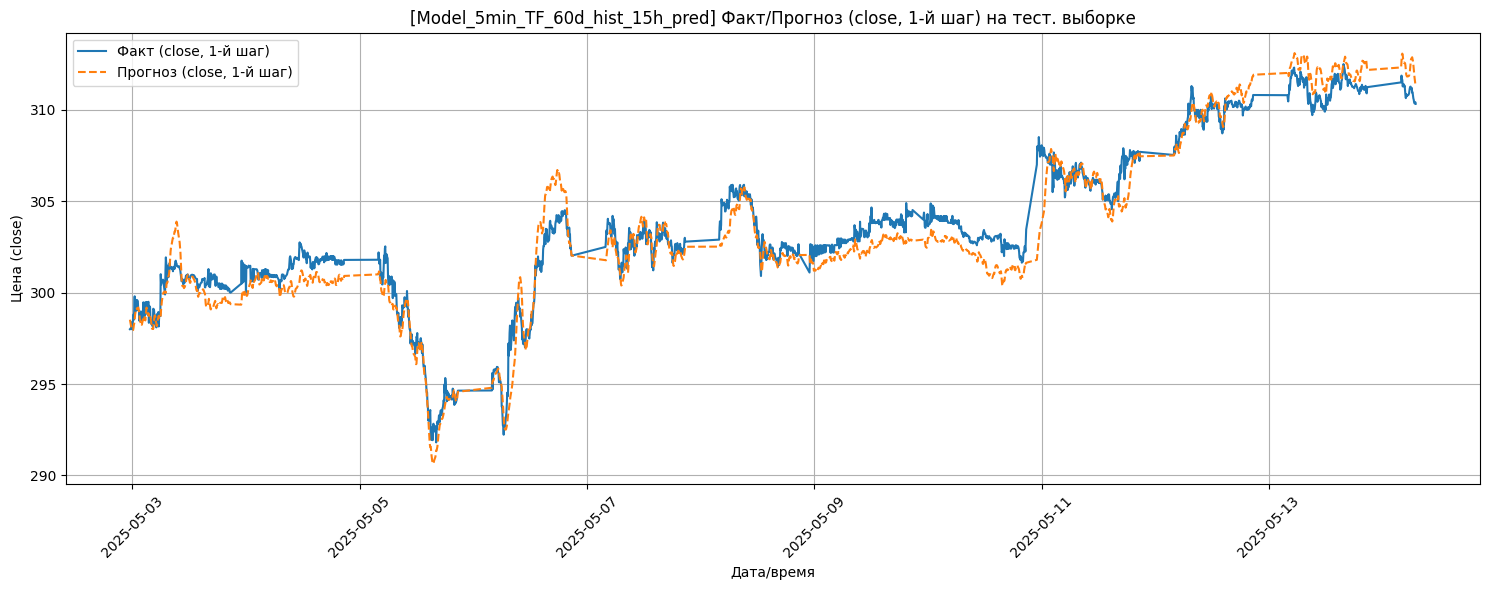


[Model_5min_TF_60d_hist_15h_pred] Средняя MSE по всем 180 шагам (тест): 7.1632


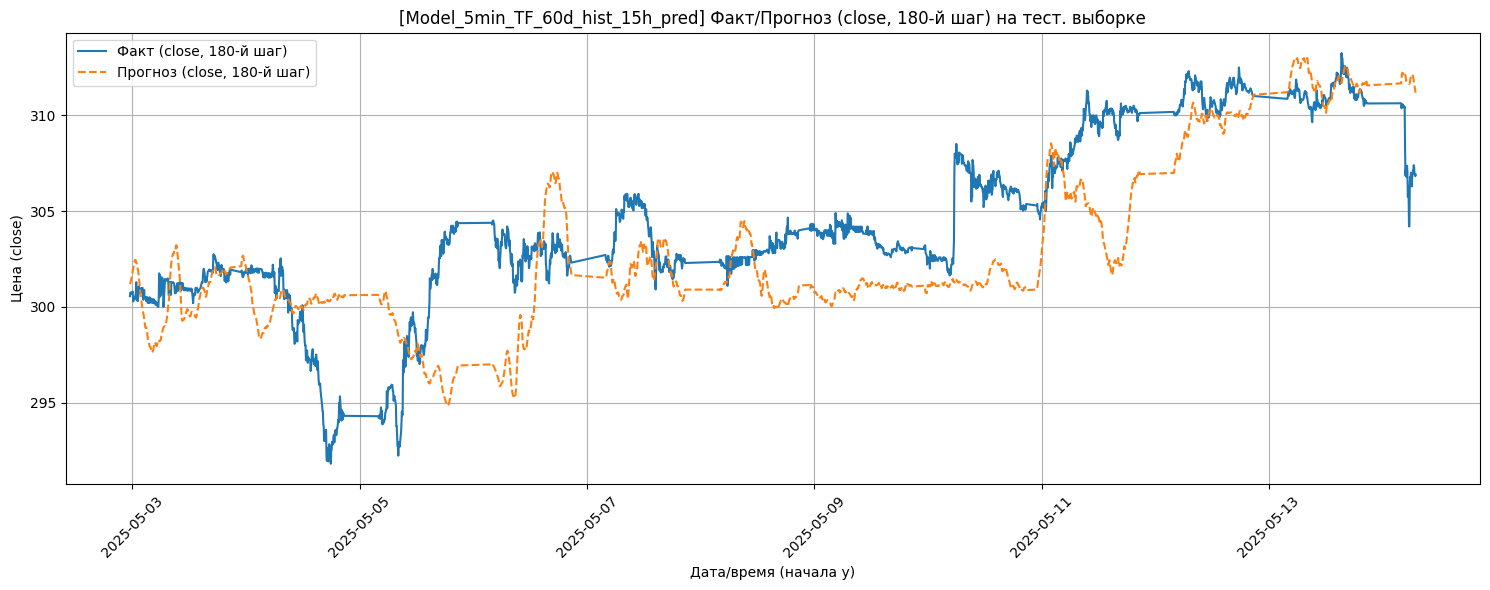


[Model_5min_TF_60d_hist_15h_pred] Рекурсивный прогноз на 180 шагов...
[Model_5min_TF_60d_hist_15h_pred] Рекурсивный прогноз завершен.


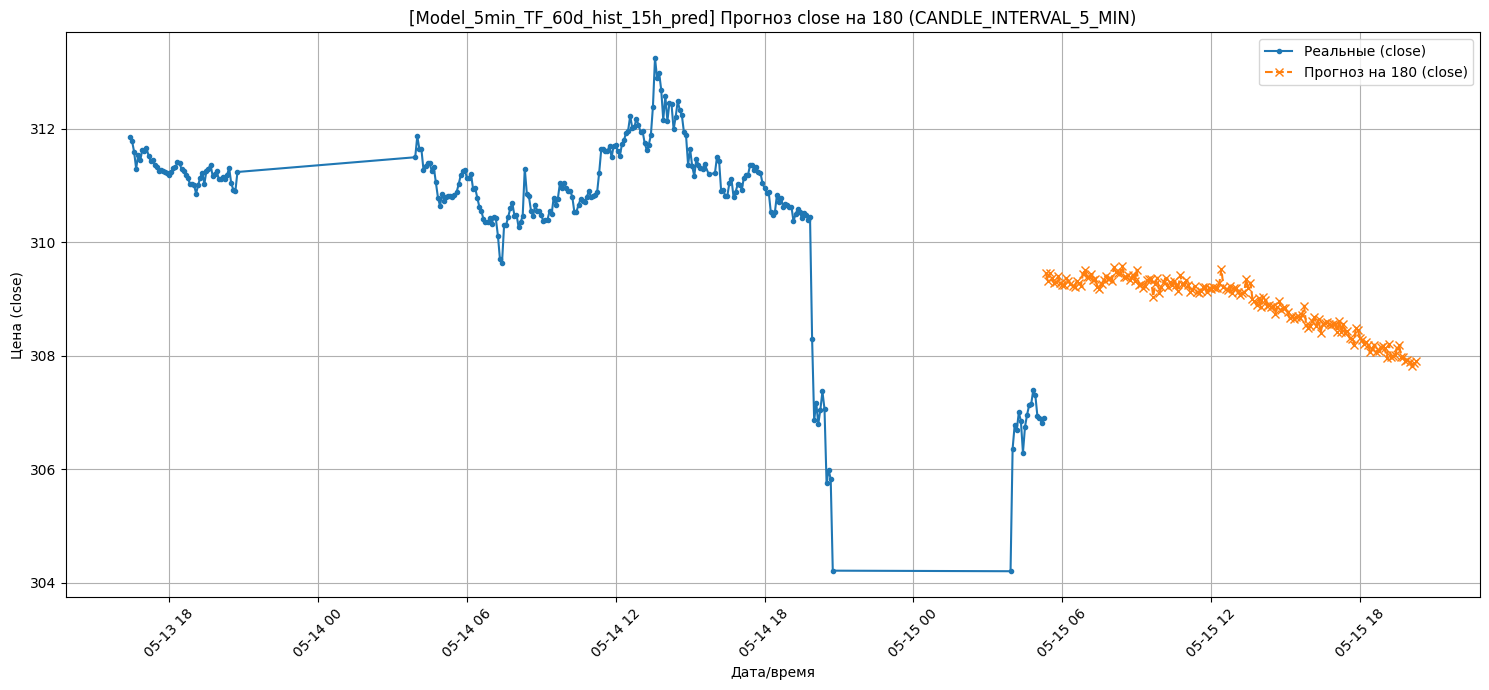


============================== Завершение обработки модели: Model_5min_TF_60d_hist_15h_pred ==============================
[Model_1min_TF_30d_hist_5h_pred] Результаты fold 1 (1-й шаг):
  MSE: 0.0687
  RMSE: 0.2622
  MAE: 0.1954
  R2: 0.9984
  MSE_PCT: 0.0001 %
  RMSE_PCT: 0.0856 %
  MAE_PCT: 0.0638 %
  R2_PCT: 99.8367 %

--- [Model_1min_TF_30d_hist_5h_pred] CV завершена ---
[Model_1min_TF_30d_hist_5h_pred] Лучшая модель из фолда 1 (MSE: 0.0687)
[Model_1min_TF_30d_hist_5h_pred] Метрики лучшей модели (валид. набор, 1-й шаг):
  MSE: 0.0687
  RMSE: 0.2622
  MAE: 0.1954
  R2: 0.9984
  MSE_PCT: 0.0001 %
  RMSE_PCT: 0.0856 %
  MAE_PCT: 0.0638 %
  R2_PCT: 99.8367 %

--- [Model_1min_TF_30d_hist_5h_pred] Финальное тестирование ---
[Model_1min_TF_30d_hist_5h_pred] Метрики на тест. выборке (1-й шаг):
  MSE: 0.1233
  RMSE: 0.3512
  MAE: 0.2311
  R2: 0.9890
  MSE_PCT: 0.0001 %
  RMSE_PCT: 0.1142 %
  MAE_PCT: 0.0751 %
  R2_PCT: 98.8975 %


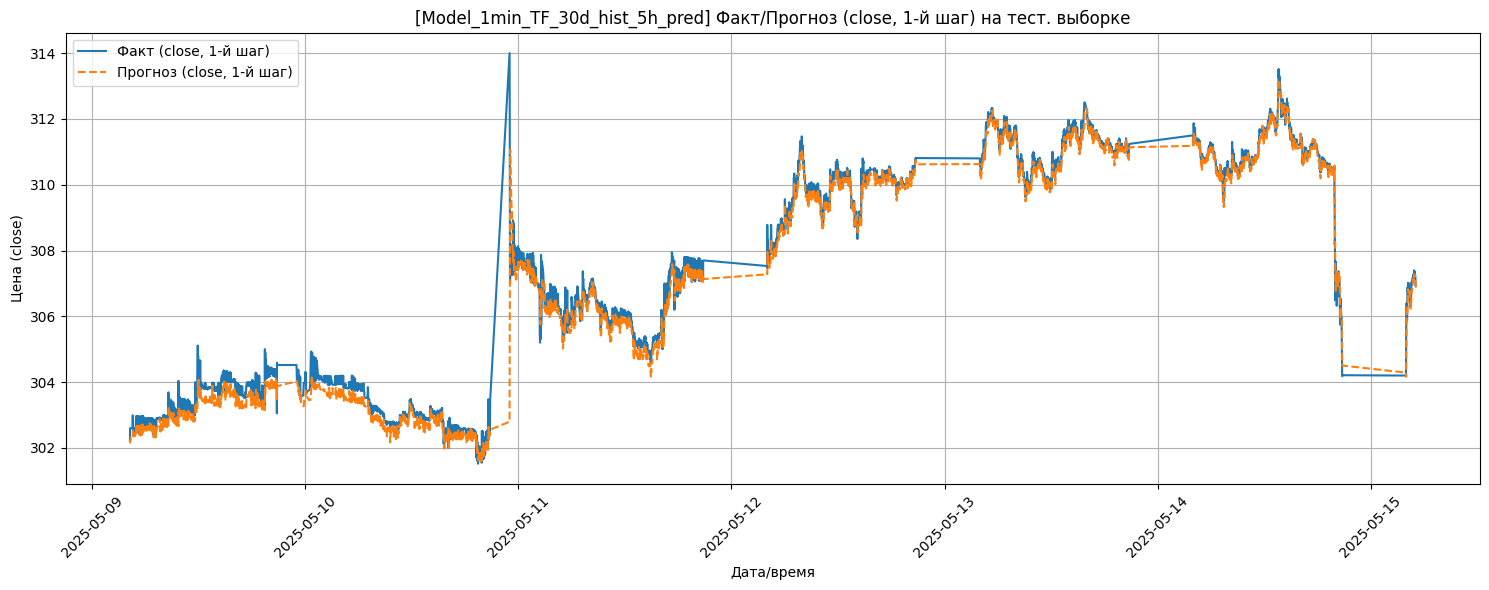


[Model_1min_TF_30d_hist_5h_pred] Средняя MSE по всем 15 шагам (тест): 0.2147


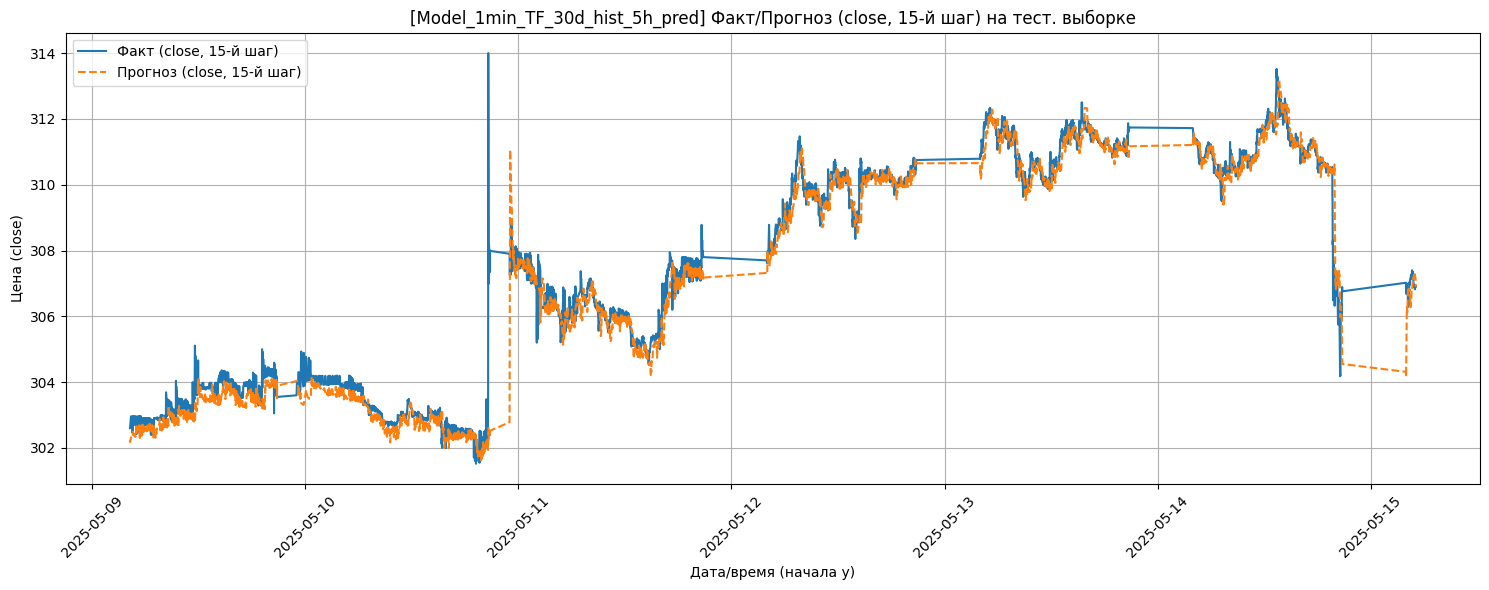


[Model_1min_TF_30d_hist_5h_pred] Рекурсивный прогноз на 300 шагов...
[Model_1min_TF_30d_hist_5h_pred] Ошибка predict_future: мало данных после ТА. Прогноз остановлен.
[Model_1min_TF_30d_hist_5h_pred] Рекурсивный прогноз завершен.


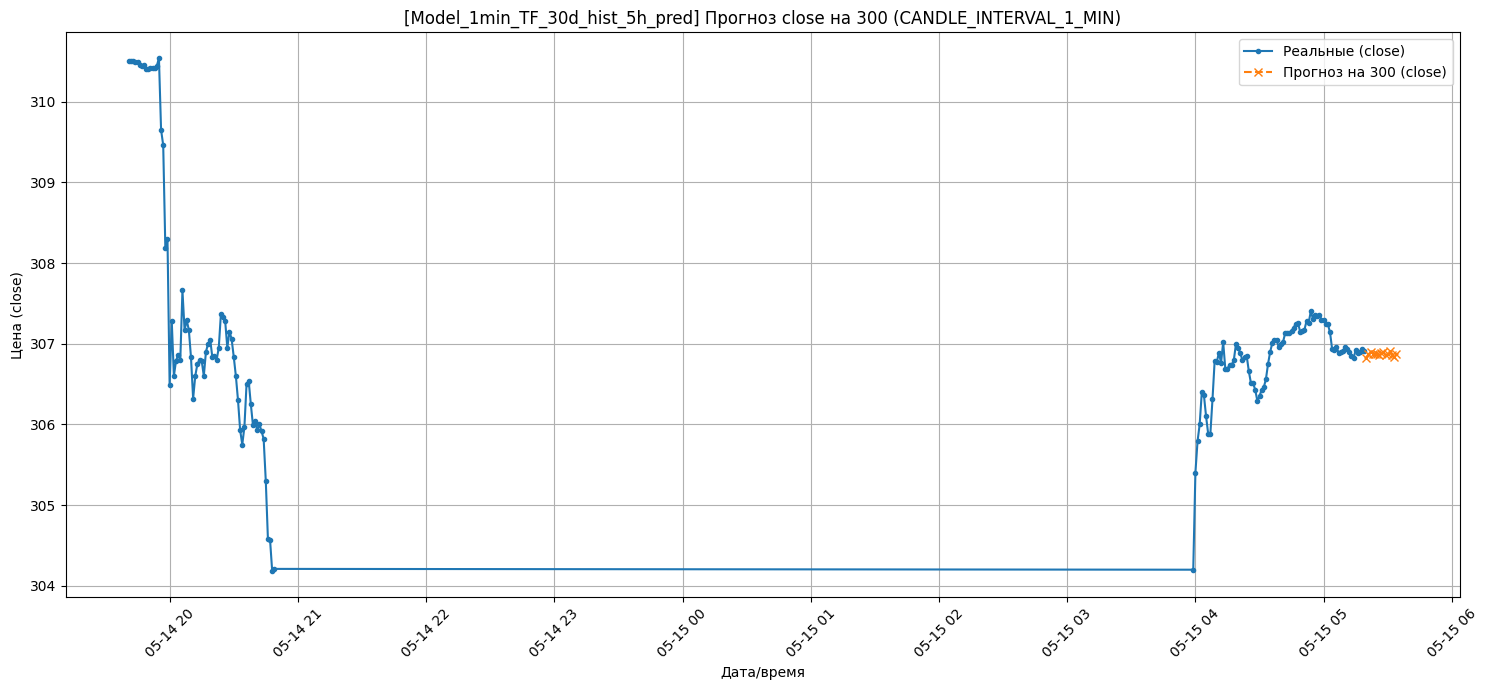


============================== Завершение обработки модели: Model_1min_TF_30d_hist_5h_pred ==============================

--- Работа всей программы завершена ---


In [17]:

if __name__ == "__main__":

    BASE_DAYS_HISTORY = 30
    BASE_CANDLE_TIMEFRAME = CandleInterval.CANDLE_INTERVAL_1_MIN
    BASE_N_STEPS_IN = 150  # Для 1-минутных свечей, 150 минут = 2.5 часа данных для входа
    BASE_N_STEPS_OUT = 15  # Прогноз на 15 минут
    BASE_FUTURE_PREDICTIONS_COUNT = 300  # Прогноз на 300 минут (5 часов) для базовой модели

    model_configs = [
        {
            "name": "Model_1min_TF_30d_hist_5h_pred",  # Базовая модель на 1-минутках
            "days_history": BASE_DAYS_HISTORY,
            "candle_timeframe": BASE_CANDLE_TIMEFRAME,
            "n_steps_in": BASE_N_STEPS_IN,
            "n_steps_out": BASE_N_STEPS_OUT,
            "future_predictions": BASE_FUTURE_PREDICTIONS_COUNT
        },
        {
            "name": "Model_5min_TF_60d_hist_15h_pred",  # Модель на 5-минутках, прогноз на 15 часов
            "days_history": 60,
            "candle_timeframe": CandleInterval.CANDLE_INTERVAL_5_MIN,
            # n_steps_out: 15 часов / 5 минут на свечу = 15 * 12 = 180 свечей на выход
            "n_steps_out": (15 * 60) // 5,
            # n_steps_in: в 1.5-2 раза больше, чем n_steps_out. Пусть будет ~1.5x
            # Пример: 180 * 1.5 = 270 свечей на вход (270 * 5 мин = 22.5 часа данных для входа)
            "n_steps_in": int(((15 * 60) // 5) * 1.5),
            "future_predictions": (15 * 60) // 5  # Прогноз на 15 часов
        },
        {
            "name": "Model_10min_TF_90d_hist_1d_pred",  # Модель на 10-минутках, прогноз на 1 сутки
            "days_history": 90,
            "candle_timeframe": CandleInterval.CANDLE_INTERVAL_10_MIN,
            # n_steps_out: 24 часа / 10 минут на свечу = 24 * 6 = 144 свечи на выход
            "n_steps_out": (24 * 60) // 10,
            # n_steps_in: 144 * 1.5 = 216 свечей на вход (216 * 10 мин = 36 часов данных для входа)
            "n_steps_in": int(((24 * 60) // 10) * 1.5),
            "future_predictions": (24 * 60) // 10  # Прогноз на 1 сутки
        }
    ]

    # --- Конфигурация параллельного обучения моделей ---
    MIN_DESIRED_WORKERS = 12

    cpu_cores = os.cpu_count()
    if cpu_cores is None:
        print(
            f"Предупреждение: Не удалось определить количество CPU ядер. Будет использовано до {MIN_DESIRED_WORKERS} потоков для моделей.")
        max_cpu_based_workers = MIN_DESIRED_WORKERS
    else:
        max_cpu_based_workers = cpu_cores
        print(f"Обнаружено {cpu_cores} CPU ядер.")

    max_workers_before_min = min(len(model_configs), max_cpu_based_workers)

    if max_workers_before_min >= MIN_DESIRED_WORKERS:
        MAX_MODEL_WORKERS = MIN_DESIRED_WORKERS
    else:  # Если моделей или CPU меньше, чем MIN_DESIRED_WORKERS
        MAX_MODEL_WORKERS = max_workers_before_min

    # Гарантируем, что есть хотя бы 1 воркер, если есть модели
    if len(model_configs) > 0 and MAX_MODEL_WORKERS <= 0:
        MAX_MODEL_WORKERS = 1
    elif len(model_configs) == 0:
        MAX_MODEL_WORKERS = 0

    print(f"INFO: Запуск обучения для {len(model_configs)} моделей.")
    print(f"INFO: Запрошено минимум {MIN_DESIRED_WORKERS} потоков для моделей.")
    print(f"INFO: Максимальное количество одновременно обучаемых моделей (MAX_MODEL_WORKERS): {MAX_MODEL_WORKERS}")
    if MAX_MODEL_WORKERS > 1:
        print(
            "INFO: Если используется GPU, УБЕДИТЕСЬ, что TensorFlow настроен для роста памяти GPU (memory growth), иначе установите меньшее значение MAX_MODEL_WORKERS (например, 1).")
        print(
            "INFO: В противном случае TensorFlow может занять всю память GPU на первой модели, и остальные не запустятся.")

    if len(model_configs) > 0 and MAX_MODEL_WORKERS > 0:
        with ThreadPoolExecutor(max_workers=MAX_MODEL_WORKERS) as executor:
            futures = [executor.submit(run_model_pipeline, config) for config in model_configs]

            for i, future in enumerate(as_completed(futures)):
                try:
                    future.result()
                except Exception as e:
                    with print_lock:
                        print(
                            f"КРИТИЧЕСКАЯ ОШИБКА (поток {i + 1}): Обучение одной из моделей завершилось с исключением на верхнем уровне: {e}")
                        import traceback

                        print(traceback.format_exc())
    elif len(model_configs) == 0:
        print("INFO: Нет конфигураций моделей для обучения.")
    else:  # MAX_MODEL_WORKERS оказался 0, хотя модели есть - такого быть не должно при текущей логике, но на всякий случай
        print("INFO: MAX_MODEL_WORKERS равен 0, обучение не будет запущено.")

    with print_lock:
        print("\n--- Работа всей программы завершена ---")